# The outline score as one Fourier coefficient: do the others matter?

The app's score is harmonic 1 of the discrete Fourier transform (DFT) of the outline's variance round the mite: 128 rays give the harmonics $A_0 \dots A_{64}$, and the score is $A_1$ (`report/fourier_and_brownian_motion.md`). This report shows the whole DFT of moving and still recordings, fits a logistic regression on all 65 harmonics, and asks with SHAP values which harmonics it relies on.

The data are every labelled moving/still recording of six datasets (2,250 recordings, 847 moving): `poke_test_oct` (90 frames), `GT_oct_2` and `Ground_truth_oct_26_final` (10 frames), `ground_truth_60min`, `ground_truth_90min` and `sample_data` (30 frames). `Ground_truth_oct_26_final` is used only before its first poke, after which its plates shake. The long run is left out, because its labels are the score's own calls. `scripts/outline_fourier.py` computes the DFT from the frames as the app cuts them, and its $A_1$ equals the app's score.

## Findings

- **When a mite moves, its whole DFT rises, not one harmonic.** Moving recordings lie above still ones at every harmonic: about 90 times at A₁, still about 8 times at A₆₄.
- **A regression on all 65 harmonics separates moving from still hardly better than the score alone:** held-out AUC 0.998 against 0.996.
- **SHAP: the regression relies on the low harmonics, A₀ to A₈, with A₀, A₁ and A₂ the largest one by one.** Above A₈ the harmonics have large SHAP values one by one, but neighbours push in opposite directions and cancel. Added up by group, they contribute little. A₀ to A₂ alone do as well as all 65 (0.998).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c85"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
np.seterr(divide="ignore", invalid="ignore")

DATASETS = ["poke_test_oct", "GT_oct_2", "ground_truth_60min", "ground_truth_90min", "sample_data", "Ground_truth_oct_26_final"]
SHAKY_FROM = {"Ground_truth_oct_26_final": 30}   # its first poke: the plates shake from there on

A, moving, mite, dataset, frames = [], [], [], [], []
for index, name in enumerate(DATASETS):
    kept = np.load(ROOT / "results" / "scripts" / f"outline_fourier_{name}.npz")
    harmonics = np.abs(kept["series"].sum(axis=2))          # (mites, recordings, 65): A_0 .. A_64
    chosen = kept["labelled"] & (harmonics[..., 0] > 0)
    chosen[:, SHAKY_FROM.get(name, chosen.shape[1]):] = False
    A.append(harmonics[chosen])
    moving.append(kept["moving"][chosen])
    mite.append(index * 1000 + np.broadcast_to(np.arange(chosen.shape[0])[:, None], chosen.shape)[chosen])
    dataset.append(np.full(chosen.sum(), name))
    frames.append(np.full(chosen.sum(), int(kept["frames"])))
A, moving, mite, dataset, frames = map(np.concatenate, (A, moving, mite, dataset, frames))
HARMONICS = np.arange(A.shape[1])
print(f"{len(A)} recordings ({moving.sum()} moving) of {len(DATASETS)} datasets, harmonics 0 .. {HARMONICS[-1]}")

2250 recordings (847 moving) of 6 datasets, harmonics 0 .. 64


## The DFT of moving and still recordings

Each recording's $A_h$, in multiples of the noise floor. The noise in $A_1 \dots A_{64}$ shrinks with the number of frames $N$, as $\sqrt{2/N}$, so those are multiplied by $\sqrt{N/2}$ to put 10-, 30- and 90-frame recordings on one scale; $A_0$ does not shrink and is left as it is. The lines are medians, and the bands hold the middle half of the recordings.

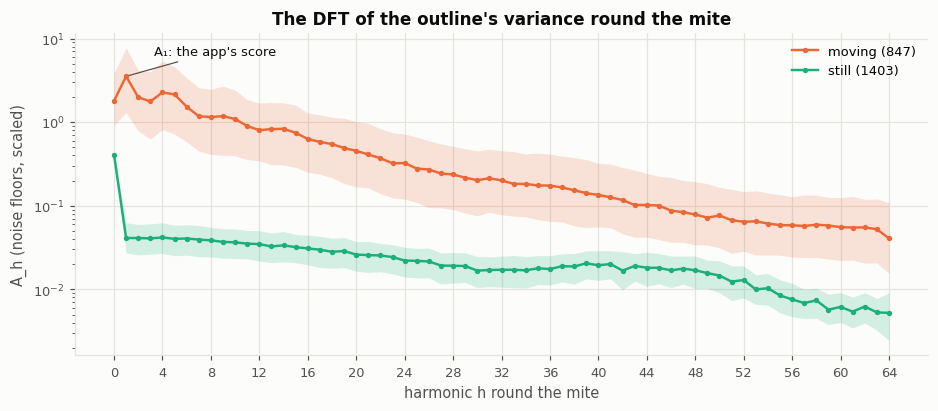

In [2]:
features = A * np.sqrt(frames / 2)[:, None]
features[:, 0] = A[:, 0]

fig, ax = plt.subplots(figsize=(10, 3.8))
for mask, color, label in [(moving, ORANGE, f"moving ({moving.sum()})"), (~moving, AQUA, f"still ({(~moving).sum()})")]:
    low, mid, high = np.percentile(features[mask], [25, 50, 75], axis=0)
    ax.fill_between(HARMONICS, low, high, color=color, alpha=0.18, linewidth=0)
    ax.plot(HARMONICS, mid, color=color, marker="o", markersize=2.5, linewidth=1.6, label=label)
ax.annotate("A₁: the app's score", (1, np.median(features[moving, 1])), xytext=(18, 14), textcoords="offset points",
            fontsize=8.5, color=INK, arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8})
ax.set(yscale="log", xlabel="harmonic h round the mite", ylabel="A_h (noise floors, scaled)", xticks=HARMONICS[::4],
       title="The DFT of the outline's variance round the mite")
ax.legend(loc="upper right")
plt.show()

A moving mite raises the whole spectrum, by a factor of 10 to 30 at the low harmonics and less and less towards 40, where both curves level off: the outline, about 60 px round, holds no finer detail. $A_0$ (the variance all round) separates least, because still recordings have their noise there.

## A logistic regression on all 65 harmonics

The features are $\log A_h$ as plotted above, standardised. Each mite is scored by a model that never saw it (5 folds by mite), and the result is set against the score alone.

In [3]:
X = np.log(np.maximum(features, 1e-6))
regression = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced"))

held_out = np.zeros(len(X))
for train, test in GroupKFold(5).split(X, moving, mite):
    held_out[test] = regression().fit(X[train], moving[train]).decision_function(X[test])
def held_out_auc(columns):
    p = np.zeros(len(X))
    for train, test in GroupKFold(5).split(X, moving, mite):
        p[test] = regression().fit(X[train][:, columns], moving[train]).decision_function(X[test][:, columns])
    return roc_auc_score(moving, p)


display(pd.DataFrame({"AUC": {"the score A_1 alone": roc_auc_score(moving, A[:, 1]),
                              "regression on all 65 harmonics (held out)": roc_auc_score(moving, held_out),
                              "regression on A_0, A_1, A_2 (held out)": held_out_auc([0, 1, 2])}}).round(4))

,AUC
the score A_1 alone,0.9961
regression on all 65 harmonics (held out),0.9978
"regression on A_0, A_1, A_2 (held out)",0.9982


## SHAP values: what the regression relies on

The regression is fitted once on all the recordings. A SHAP value says how much one harmonic pushes one recording's prediction towards moving (positive) or still (negative), against the average recording. For a linear model it is exact: weight × (the feature's value − its mean), which is what `shap.LinearExplainer` computes.

Left: what each harmonic adds between moving and still recordings, with its sign: its mean SHAP value over the moving recordings minus its mean over the still ones (over all recordings together each harmonic's SHAP averages 0). Positive bars push moving recordings towards "moving", negative ones (pale) push them back towards "still". Below it, the running total from harmonic 0 up: where it only wanders and comes back, neighbouring harmonics cancel each other. Right: the 12 most important harmonics, one dot per recording, coloured by the harmonic's value (red high, blue low). The table below adds SHAP values up by group of harmonics: where the group's value is much smaller than its members' added up, the members cancel each other.

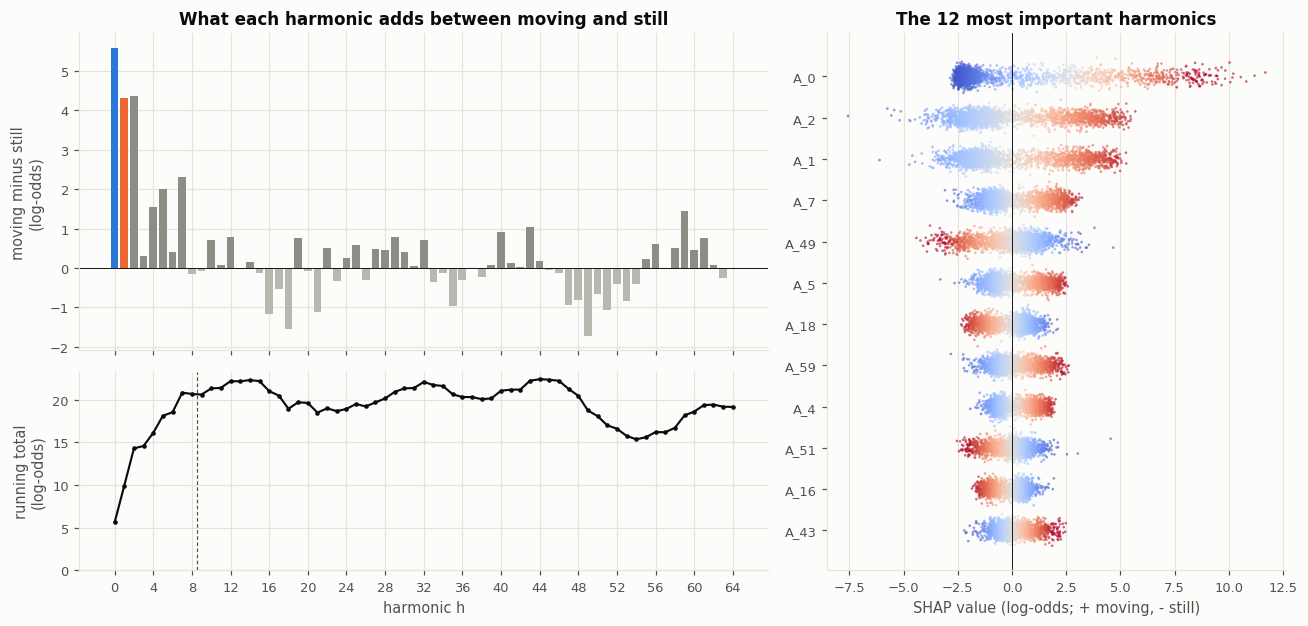

,"members' mean |SHAP|, added up",mean |SHAP| of the group
A_0,2.72,2.72
A_1,2.05,2.05
A_2,2.08,2.08
A_3 .. A_8,3.21,3.05
A_9 .. A_30,5.51,0.61
A_31 .. A_64,8.91,1.63


In [4]:
model = regression().fit(X, moving)
standardised = model[0].transform(X)
shap_values = standardised * model[-1].coef_[0]          # (recordings, harmonics); the mean of each column is 0
importance = np.abs(shap_values).mean(axis=0)
top = np.argsort(importance)[::-1][:12]

fig = plt.figure(figsize=(12, 5.8))
grid = fig.add_gridspec(2, 2, width_ratios=[1.5, 1], height_ratios=[1.6, 1])
left = fig.add_subplot(grid[0, 0])
below = fig.add_subplot(grid[1, 0], sharex=left)
right = fig.add_subplot(grid[:, 1])
# signed: each harmonic's mean SHAP over the moving recordings minus over the still ones (over all recordings it is 0)
push = shap_values[moving].mean(axis=0) - shap_values[~moving].mean(axis=0)
left.bar(HARMONICS, push, color=[ORANGE if h == 1 else BLUE if h == 0 else (GREY if v > 0 else "#b8b7b0") for h, v in zip(HARMONICS, push)],
         width=0.8)
left.axhline(0, color=INK, linewidth=0.6)
left.set(ylabel="moving minus still\n(log-odds)", title="What each harmonic adds between moving and still")
left.tick_params(labelbottom=False)
below.plot(HARMONICS, np.cumsum(push), color=INK, linewidth=1.4, marker="o", markersize=2)
below.axvline(8.5, color=MUTED, linewidth=0.8, linestyle=(0, (3, 2)))
below.set(xlabel="harmonic h", ylabel="running total\n(log-odds)", xticks=HARMONICS[::4], ylim=(0, None))

rng = np.random.default_rng(0)
for row, h in enumerate(top[::-1]):
    value = standardised[:, h]
    order = rng.permutation(len(value))
    jitter = rng.normal(0, 0.12, len(value))
    right.scatter(shap_values[order, h], row + jitter[order], c=np.clip(value[order], -2.5, 2.5), cmap="coolwarm", s=3, alpha=0.6,
                  linewidths=0)
right.axvline(0, color=INK, linewidth=0.6)
right.set_yticks(range(len(top)), [f"A_{h}" for h in top[::-1]])
right.set(xlabel="SHAP value (log-odds; + moving, - still)", title="The 12 most important harmonics")
right.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# SHAP values add up: a group's contribution to a recording is the sum of its members'
groups = {"A_0": [0], "A_1": [1], "A_2": [2], "A_3 .. A_8": range(3, 9), "A_9 .. A_30": range(9, 31), "A_31 .. A_64": range(31, 65)}
display(pd.DataFrame({"members' mean |SHAP|, added up": {g: np.abs(shap_values[:, list(h)]).mean(axis=0).sum() for g, h in groups.items()},
                      "mean |SHAP| of the group": {g: np.abs(shap_values[:, list(h)].sum(axis=1)).mean() for g, h in groups.items()}}).round(2))

## What it means

- **On clean recordings, the harmonics beyond the score add almost nothing.** The regression on all 65 gains about 0.002 of AUC over the score alone, because a moving mite raises every harmonic together.
- **What the regression uses is the low harmonics. A₀, A₁ and A₂ are the largest, all three pushing towards moving when high, and A₃ to A₈ add about as much together.** A₀ to A₂ alone do as well as all 65, so A₃ to A₈ only repeat what those three already say. A₀ is the change all round the mite, A₁ the change on one side (the score), and A₂ the change on two opposite sides. A₂ can pick up a mite whose legs move on both sides, which A₁ partly cancels. A₂ and A₀ are also where shake goes, though: on the poke run's shaky recordings (left out here), they called many still recordings moving.
- **The high harmonics' large SHAP values are an artefact of their correlation.** Neighbouring harmonics carry nearly the same thing, so the regression gives some a positive weight and others a negative one (A₄₉, A₁₈ and A₅₁ push towards still when high), and these cancel. Added up, harmonics 9 to 64 contribute little, and dropping them costs nothing. Above about 30 they are finer than the outline, about 60 px round, can resolve anyway.